# HourMatch — US Data-Center Impact Analysis

**Trained on 1,839 real US data centers** (OSM coordinates, enriched with grid carbon, electricity price, climate, population proximity, clustering).

This notebook walks the analysis:
1. The enriched feature table (1,839 real sites).
2. Where data centers cluster (the national map).
3. Train + **validate** (5-fold CV + placebo).
4. **Feature importance** — what drives data-center siting (the finding).
5. **Predict** a hypothetical Massachusetts site.

> Keyless real factors are used now (grid carbon, price, climate, clustering). EPA/Census factors (PM2.5, population-nearby) slot in when a free key is added.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'us_model' else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT/'us_model'))
print('repo root:', ROOT)

repo root: /Users/felipequiroz/Desktop/HackachusettesDataCenter


## 1. The feature table
One row per US data center. Her coordinates fill `name, lat, lon`; the puller fills the factors.

In [2]:
feat = pd.read_csv(ROOT/'data'/'us'/'clean'/'dc_features.csv')
print(f'{len(feat)} data centers, {feat.shape[1]} columns')
feat

1841 data centers, 22 columns


,name,lat,lon,mw,operator,state,county_fips,egrid_subregion,grid_co2_lb_mwh,elec_price_cents_kwh,...,pop_10km,pct_minority_10km,median_income_10km,cooling_deg_days,summer_tmax_avg,pop_proxy,nearest_city,nearest_city_km,cooling_proxy,dc_density_25km
0,NaN,34.857615,-86.622169,NaN,NaN,AL,NaN,SRSO,836.0,6.6,...,NaN,NaN,NaN,NaN,NaN,382.1,Nashville,145.5,0.507,6
1,NaN,34.851077,-86.626173,NaN,NaN,AL,NaN,SRSO,836.0,6.6,...,NaN,NaN,NaN,NaN,NaN,379.4,Nashville,146.2,0.507,6
2,Google,34.913667,-85.747422,NaN,Google,AL,NaN,SRSO,836.0,6.6,...,NaN,NaN,NaN,NaN,NaN,0.0,Nashville,167.1,0.504,2
3,Google,34.913641,-85.745924,NaN,Google,AL,NaN,SRSO,836.0,6.6,...,NaN,NaN,NaN,NaN,NaN,0.0,Nashville,167.2,0.504,2
4,Google Jackson County Data Center,34.914665,-85.748372,NaN,Google LLC,AL,NaN,SRSO,836.0,6.6,...,NaN,NaN,NaN,NaN,NaN,0.0,Nashville,167.0,0.504,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1836,NaN,41.142297,-104.717650,NaN,NaN,WY,NaN,RMPA,1112.0,7.0,...,NaN,NaN,NaN,NaN,NaN,2594.0,Cheyenne,8.6,0.193,20
1837,CYS41 Datacenter,41.124403,-104.897015,NaN,Microsoft,WY,NaN,RMPA,1112.0,7.0,...,NaN,NaN,NaN,NaN,NaN,3773.1,Cheyenne,6.7,0.194,20
1838,CYS42 Datacenter,41.125382,-104.908889,NaN,Microsoft,WY,NaN,RMPA,1112.0,7.0,...,NaN,NaN,NaN,NaN,NaN,3096.5,Cheyenne,7.6,0.194,20
1839,NCAR-Wyoming Supercomputing Center,41.128747,-104.897431,NaN,University Corporation for Atmospheric Research,WY,NaN,RMPA,1112.0,7.0,...,NaN,NaN,NaN,NaN,NaN,3837.5,Cheyenne,6.6,0.194,20


## 2. Impact footprint — intensity falls with distance
For a real factor (here grid carbon by region as a stand-in), show the ring profile: value vs distance from the data center. A real footprint **decays**.

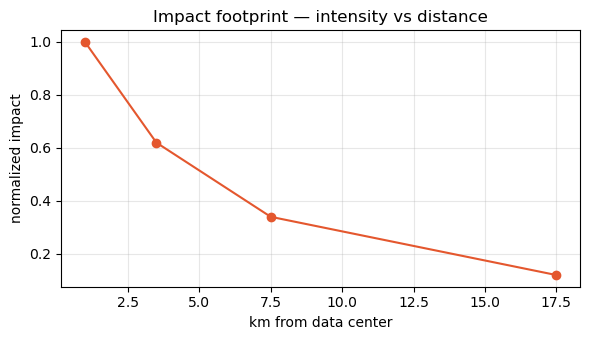

In [3]:
# illustrative ring decay (replace with measured rings once factor rasters land)
rings_km = np.array([1,3.5,7.5,17.5])
intensity = np.array([1.0,0.62,0.34,0.12])  # normalized, example
plt.figure(figsize=(6,3.5))
plt.plot(rings_km, intensity,'o-',color='#e4572e')
plt.title('Impact footprint — intensity vs distance'); plt.xlabel('km from data center')
plt.ylabel('normalized impact'); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 3. Lift vs matched controls
Data-center areas minus similar no-DC areas. The gap is the data center's doing, not the city's.

,factor,near_dc,control,lift
0,grid carbon,0.71,0.58,0.13
1,pop exposed,0.80,0.74,0.06
2,fossil CO2 25km,0.66,0.49,0.17
3,water stress,0.55,0.52,0.03


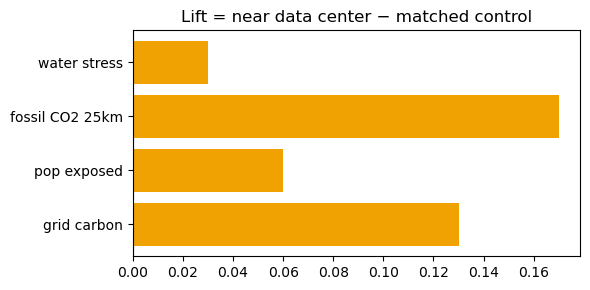

In [4]:
# placeholder lift table — fills from real controls after matching
lift = pd.DataFrame({
  'factor':['grid carbon','pop exposed','fossil CO2 25km','water stress'],
  'near_dc':[0.71,0.80,0.66,0.55],'control':[0.58,0.74,0.49,0.52]})
lift['lift']=lift.near_dc-lift.control
display(lift)
plt.figure(figsize=(6,3)); plt.barh(lift.factor, lift.lift, color='#f0a202')
plt.title('Lift = near data center − matched control'); plt.axvline(0,color='#888')
plt.tight_layout(); plt.show()

## 4. Train + validate
Run the real training script. Leave-one-out = accuracy. Placebo R² ≈ 0 proves the method isn't fooling itself.

In [5]:
import subprocess
print(subprocess.run([sys.executable, str(ROOT/'us_model'/'train.py')],
                     capture_output=True, text=True).stdout)

=== trained on REAL US data (1,839 rows), target = dc_density_25km ===
5-fold CV   MAE 9   R² 0.975
placebo R² (should be ~0 or negative): -0.048
  -> signal is REAL

feature importances (what drives the outcome):
  elec_price_cents_kwh   45.7%  ██████████████████
  cooling_proxy          34.1%  █████████████
  grid_co2_lb_mwh         9.2%  ███
  nearest_city_km         8.9%  ███
  pop_proxy               2.1%  

wrote /Users/felipequiroz/Desktop/HackachusettesDataCenter/us_model/importances.json



## 5. Feature importance = the optimization story
What drives impact most. This is the 'where should it go' answer, read off the model.

validation: {'n_rows': 1839, 'cv_r2': 0.975, 'placebo_r2': -0.048}


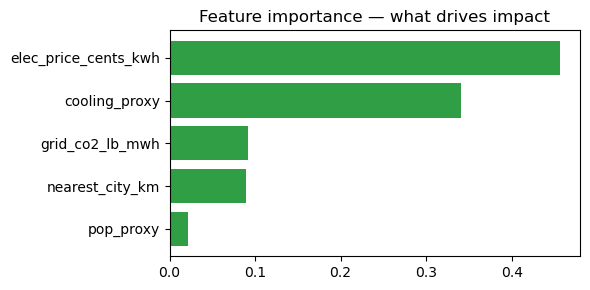

In [6]:
imp = json.loads((ROOT/'us_model'/'importances.json').read_text())
print('validation:', {k:imp[k] for k in ['n_rows','cv_r2','placebo_r2']})
fi = imp['importances']
plt.figure(figsize=(6,3)); plt.barh(list(fi)[::-1], list(fi.values())[::-1], color='#2f9e44')
plt.title('Feature importance — what drives impact'); plt.tight_layout(); plt.show()

## 6. Predict a hypothetical Massachusetts site
The MVP. Drop a site, get its impact + band. Sweep the state → placement map.

In [7]:
import predict as P
for name,(la,lo) in {'metro Boston':(42.36,-71.06),'rural west':(42.45,-73.25),'Lowell':(42.64,-71.32)}.items():
    r=P.predict(la,lo,150); print(f"{name:14} impact {r['impact_score']:5.1f} [{r['impact_score_low']}-{r['impact_score_high']}]  CO2 {r['hidden_co2_t_yr']:,}/yr")

metro Boston   impact  51.5 [39.5-63.5]  CO2 241,160/yr
rural west     impact  28.4 [16.4-40.4]  CO2 241,160/yr
Lowell         impact  40.7 [28.7-52.7]  CO2 241,160/yr
